# 07 · 第二课：让真实 Qwen 一步一步生成回答

上一课已经读过结构，现在把真实参数加载进来。我们使用同一版本的 **Qwen3-0.6B**，在本机处理一句中文，观察输入、张量、下一 token 和完整回答。

你打开就能看到教师执行保存的结果；这些是实际模型输出，不是预设答案，也不代表你已经完成实践。按顺序运行时，你可以直接改 `QUESTION` 看变化。无需租 GPU、无需 API key；首次需要下载约 1.2 GB 权重，保存在 Hugging Face 本机缓存，不进入 Git。

本课路线：**先看图 → 真实回答 → 拆输入 → 拆一次 forward → 手动生成 → KV cache 对照 → 速度与内存**。不设猜数字和填空题。

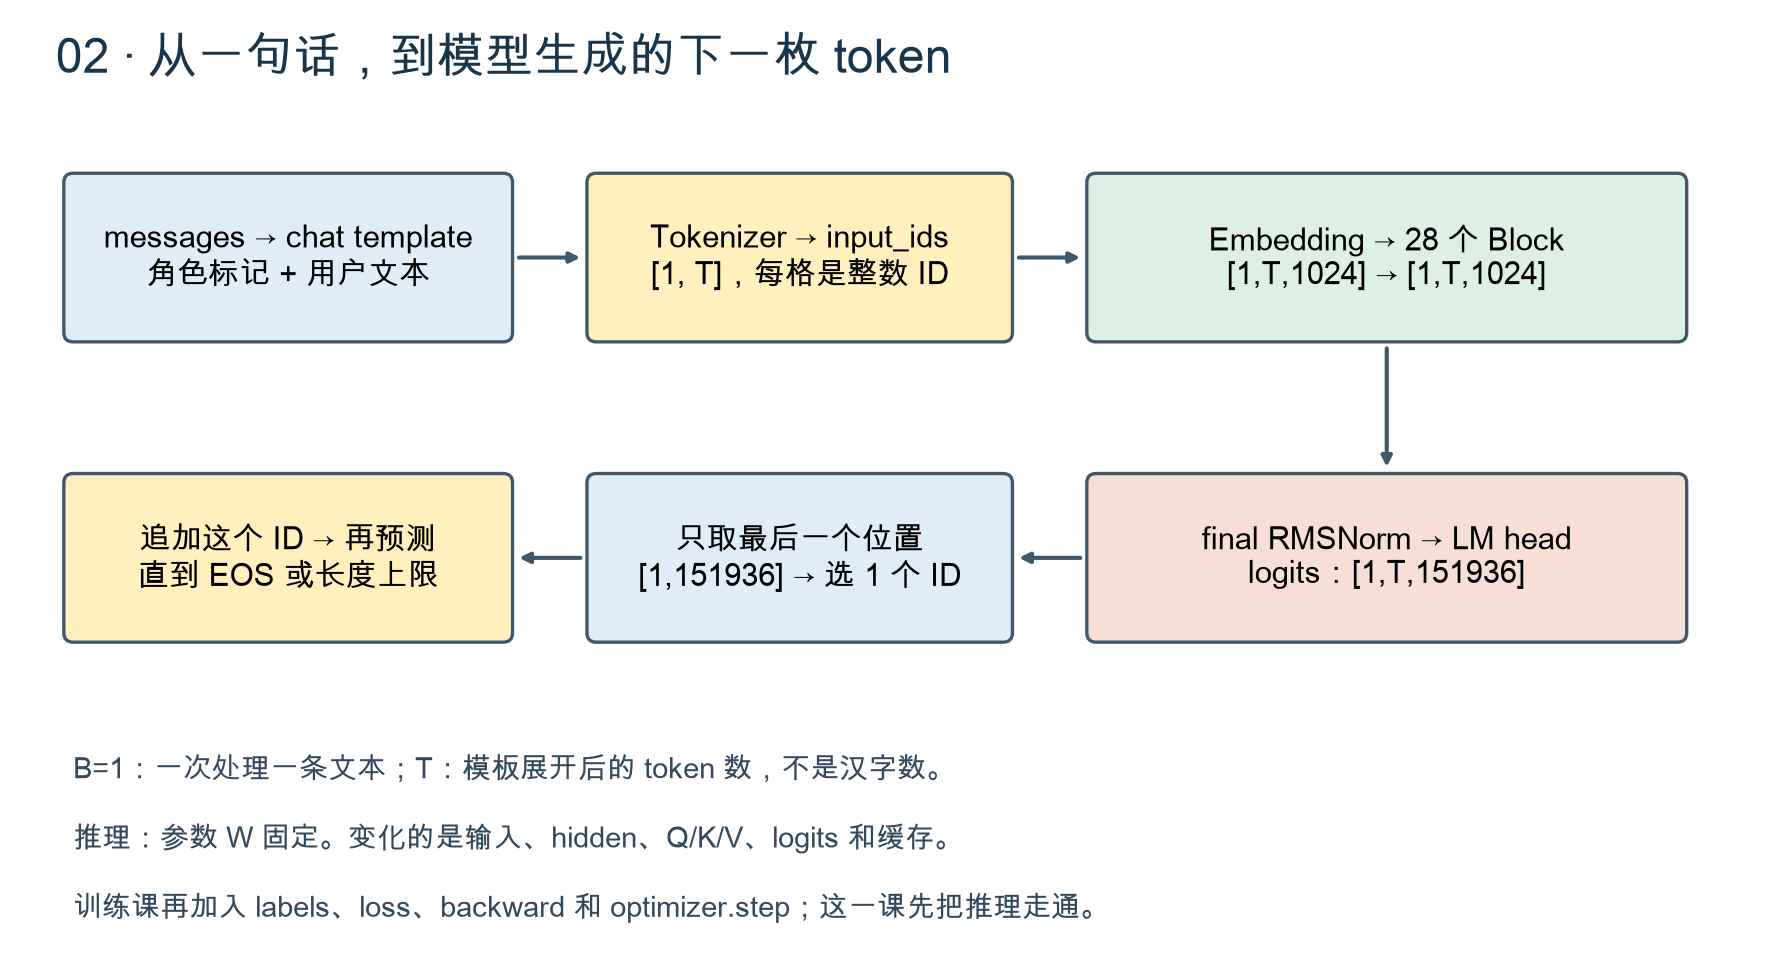

## 0 · 准备环境，只加载一次

在仓库根目录的终端运行：
```bash
uv sync --extra inference
```
然后选择本项目的 `llm-from-zero` 内核。下面打印的 Python 路径应指向项目 `.venv`。如果刚安装依赖，请重启内核再从头运行。

本课固定 Transformers 4.57.3 和模型 revision；不执行模型仓库的远程 Python。默认优先使用 Mac 的 MPS，无法使用时回到 CPU。为观察缓存路径的数值一致性使用 float32：权重约 2.22 GiB，实际进程内存还包括激活、缓存和框架开销。

In [1]:
from pathlib import Path
from datetime import datetime
import sys, json, platform, gc
import torch
import transformers
from IPython.display import display, Markdown

# 从仓库根目录或课件目录启动都能找到工具。
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '07-modern-llm').is_dir())
LESSON = ROOT / '07-modern-llm' / '02-real-inference'
sys.path.insert(0, str(LESSON))
from inference_utils import MODEL_ID, REVISION, manual_generate, check_cache, benchmark, eos_ids

device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.executable)
print('torch:', torch.__version__, '| transformers:', transformers.__version__)
print('设备:', device, '| dtype: float32')

Python: /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/bin/python
torch: 2.14.1 | transformers: 4.57.3
设备: mps | dtype: float32


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, trust_remote_code=False)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, trust_remote_code=False,
    dtype=torch.float32, attn_implementation='sdpa',
).to(device)
model.eval()  # 关闭训练行为；下面的 inference_mode 另外关闭梯度记录。
print('真实模型:', type(model).__name__)
print('参数量:', f'{sum(p.numel() for p in model.parameters()):,}')
print('层数:', len(model.model.layers), '| 共享词表权重:', model.lm_head.weight is model.model.embed_tokens.weight)

真实模型: Qwen3ForCausalLM
参数量: 596,049,920
层数: 28 | 共享词表权重: True


## 1 · 先看到真实回答

这里的 Qwen3-0.6B 是经过后训练、支持对话与思考模式的模型，不能把它当作随机初始化网络或纯 Base 模型。

先关闭思考模式，便于看清普通回答的生成。`enable_thinking=False` 控制的是模板/生成行为，不是删除网络层，也不是证明模型内部“不推理”。本课不训练、不更新 W。

In [3]:
QUESTION = '请用一句话解释什么是自回归生成。'
messages = [{'role': 'user', 'content': QUESTION}]
prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
# 模板已经包含特殊 token，不能再重复添加。
inputs = tokenizer(prompt, add_special_tokens=False, return_tensors='pt').to(device)
input_ids = inputs['input_ids']
T = input_ids.shape[1]
# 显式覆盖模型自带的采样设置；None 表示本次不用这些采样参数。
with torch.inference_mode():
    generated = model.generate(**inputs, max_new_tokens=64, do_sample=False,
                               temperature=None, top_p=None, top_k=None, use_cache=True)
answer_ids = generated[0, T:]
answer = tokenizer.decode(answer_ids, skip_special_tokens=True)
print('问题:', QUESTION)
print('模型回答:', answer)
print('输入/新生成 token 数:', T, '/', len(answer_ids))
print('停止原因:', 'EOS' if answer_ids[-1].item() in eos_ids(model) else '达到 64 token 上限（可能未说完）')

问题: 请用一句话解释什么是自回归生成。
模型回答: 自回归生成是一种通过历史数据生成未来数据的技术，使得模型能够根据过去的输入生成当前或未来的输出。
输入/新生成 token 数: 21 / 25
停止原因: EOS


## 2 · 模型实际收到的不是 Python 消息字典

`messages` 是应用接口的数据结构。chat template 把角色、内容和轮次边界拼成文本，tokenizer 再转换成整数。

刚才的回答可以说明模型生成成功，但“通过历史数据生成未来数据”的说法比较笼统；对本课，更准确的是“根据已有 token 前缀逐个预测下一个 token”。我们保留原始输出，不把它修改成标准答案。

下面依次显示：原始文字、带角色标记的文本、真正进入模型的 ID。**T 包含角色标记和模板内容，不等于汉字数。** 模板末尾的空 `<think>` 段来自关闭思考模式的设置，不是本次模型生成的思维链。

In [4]:
print('原始用户文字:', QUESTION)
print('模板展开后:\n' + prompt)
print('input_ids.shape:', tuple(input_ids.shape))
print('input_ids:', input_ids[0].tolist())
print('attention_mask:', inputs['attention_mask'][0].tolist())
print('\n逐 token 查看（tokenizer 的原始片段不一定是可读汉字）：')
for position, token_id in enumerate(input_ids[0].tolist()):
    print(f'{position:2d}  ID={token_id:6d}  piece={tokenizer.convert_ids_to_tokens(token_id)!r}')

原始用户文字: 请用一句话解释什么是自回归生成。
模板展开后:
<|im_start|>user
请用一句话解释什么是自回归生成。<|im_end|>
<|im_start|>assistant
<think>

</think>


input_ids.shape: (1, 21)
input_ids: [151644, 872, 198, 14880, 11622, 105321, 104136, 106582, 35926, 105162, 43959, 1773, 151645, 198, 151644, 77091, 198, 151667, 271, 151668, 271]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

逐 token 查看（tokenizer 的原始片段不一定是可读汉字）：
 0  ID=151644  piece='<|im_start|>'
 1  ID=   872  piece='user'
 2  ID=   198  piece='Ċ'
 3  ID= 14880  piece='è¯·'
 4  ID= 11622  piece='çĶ¨'
 5  ID=105321  piece='ä¸Ģåı¥è¯Ŀ'
 6  ID=104136  piece='è§£éĩĬ'
 7  ID=106582  piece='ä»Ģä¹Īæĺ¯'
 8  ID= 35926  piece='èĩª'
 9  ID=105162  piece='åĽŀå½Ĵ'
10  ID= 43959  piece='çĶŁæĪĲ'
11  ID=  1773  piece='ãĢĤ'
12  ID=151645  piece='<|im_end|>'
13  ID=   198  piece='Ċ'
14  ID=151644  piece='<|im_start|>'
15  ID= 77091  piece='assistant'
16  ID=   198  piece='Ċ'
17  ID=151667  piece='<think>'
18  ID=   271  piece='ĊĊ'
19  ID=151668  piece=

本例只有一条输入、没有 padding，所以 `attention_mask` 全为 1。它不等于“允许看未来”：模型内部仍然应用 causal mask。

一个汉字可能跨多个 token。单独 decode 某个 token 可能出现替换符；观察生成文本时，应 decode **整段累计 ID**。

Base 模型通常用普通文本续写；聊天模型通常按它训练时的模板输入。给同一个聊天模型直接喂裸文本，并不等于把它变回 Base。我们在此不额外下载第二个模型。

## 3 · 拆开一次 forward：每一层到底收到了什么

`model(...)` 只算预测分数，不会自己一直说下去。下面临时注册观察函数（hook），记录首层投影的实际输出形状；观察后立即移除。

B=1，T 取上面实际长度。Q 投影宽度 2048，K/V 投影宽度 1024；Q/K Norm 前先拆头，Norm 的输出排列仍是 `[B,T,头数,128]`，Attention 内部再转成 `[B,头数,T,128]`。

In [5]:
shapes = {}
def record(name):
    def hook(module, args, output):
        shapes[name] = list(output.shape)
    return hook

first = model.model.layers[0]
watched = {
    'Embedding': model.model.embed_tokens,
    '首层 RMSNorm': first.input_layernorm,
    'Q projection': first.self_attn.q_proj,
    'K projection': first.self_attn.k_proj,
    'V projection': first.self_attn.v_proj,
    'Q head norm': first.self_attn.q_norm,
    'K head norm': first.self_attn.k_norm,
    'SwiGLU gate': first.mlp.gate_proj,
    'SwiGLU down': first.mlp.down_proj,
    '最终 RMSNorm': model.model.norm,
    'LM head': model.lm_head,
}
handles = [module.register_forward_hook(record(name)) for name, module in watched.items()]
try:
    with torch.inference_mode():
        forward = model(**inputs, use_cache=False)
finally:
    for handle in handles:
        handle.remove()
for name, shape in shapes.items():
    print(f'{name:18s} {shape}')
assert forward.logits.shape == (1, T, model.config.vocab_size)

Embedding          [1, 21, 1024]
首层 RMSNorm         [1, 21, 1024]
Q projection       [1, 21, 2048]
Q head norm        [1, 21, 16, 128]
K projection       [1, 21, 1024]
K head norm        [1, 21, 8, 128]
V projection       [1, 21, 1024]
SwiGLU gate        [1, 21, 3072]
SwiGLU down        [1, 21, 1024]
最终 RMSNorm         [1, 21, 1024]
LM head            [1, 21, 151936]


## 4 · 为什么只看最后一个位置？

完整 logits 为 `[1,T,151936]`。第 i 个位置预测它后面的 token。用户输入已经确定；要继续写，就取最后一个位置的分数 `[1,151936]`。

logit 是实数分数，还不是概率。softmax 转成概率供查看或采样；**贪心 argmax 可以直接对 logits 取最大值**，因为 softmax 不改变排序。

In [6]:
next_logits = forward.logits[:, -1, :]
probabilities = next_logits.float().softmax(dim=-1)
values, indices = probabilities[0].topk(8)
print('最后位置 logits.shape:', tuple(next_logits.shape))
print('下一 token 候选（不是整句答案的概率）：')
for probability, token_id in zip(values.tolist(), indices.tolist()):
    print(f'ID={token_id:6d}  p={probability:.4f}  piece={tokenizer.convert_ids_to_tokens(token_id)!r}')
print('贪心选择:', indices[0].item())
assert indices[0].item() == answer_ids[0].item()
del forward, next_logits, probabilities  # 不保留整段大词表 logits。

最后位置 logits.shape: (1, 151936)
下一 token 候选（不是整句答案的概率）：
ID= 35926  p=0.9984  piece='èĩª'
ID=   334  p=0.0012  piece='**'
ID=104049  p=0.0001  piece='èĩªæĪĳ'
ID= 67338  p=0.0000  piece='éĢļè¿ĩ'
ID= 12092  p=0.0000  piece='Self'
ID= 18493  p=0.0000  piece='åľ¨'
ID=  2073  p=0.0000  piece='âĢľ'
ID= 19602  p=0.0000  piece='Aut'
贪心选择: 35926


## 5 · 不用 generate，亲手走 5 步

先不使用 cache，直接反复输入完整前缀。下面六行核心操作就是自回归生成：forward → 取最后位置 → 选 ID → 追加 → 再次 forward。

新生成的 token 作为下一步输入。训练时的标准 teacher forcing 则输入真实文本前缀，目标是后移一位的真实 token；不是把本课循环原封不动变成训练。

In [7]:
ids = input_ids.clone()
with torch.inference_mode():
    for step in range(5):
        output = model(input_ids=ids, attention_mask=torch.ones_like(ids), use_cache=False, logits_to_keep=1)
        next_id = output.logits[:, -1, :].argmax(dim=-1, keepdim=True)
        old_length = ids.shape[1]
        ids = torch.cat([ids, next_id], dim=1)
        print(f'第 {step+1} 步，送入 {old_length} 个 token，选中 ID={next_id.item()}')
        print('  累计生成:', repr(tokenizer.decode(ids[0, T:], skip_special_tokens=True)))
        if next_id.item() in eos_ids(model):
            break
assert torch.equal(ids[0, T:], answer_ids[:ids.shape[1]-T])
print('与 generate 的贪心前缀一致。')
del output

第 1 步，送入 21 个 token，选中 ID=35926
  累计生成: '自'
第 2 步，送入 22 个 token，选中 ID=105162
  累计生成: '自回归'


第 3 步，送入 23 个 token，选中 ID=43959
  累计生成: '自回归生成'


第 4 步，送入 24 个 token，选中 ID=101158
  累计生成: '自回归生成是一种'
第 5 步，送入 25 个 token，选中 ID=67338
  累计生成: '自回归生成是一种通过'
与 generate 的贪心前缀一致。


`logits_to_keep=1` 只让输出投影保留最后一个位置的 logits，减少词表分数的内存；没有 cache 时，前面的 Transformer 仍然处理完整前缀。

EOS 也是词表中的 ID，由模型像其他 token 一样预测出来。停止逻辑在循环外层检查它；达到 `max_new_tokens` 只是人为截断，不代表模型认为回答结束。

## 6 · 同一份参数，为什么回答可以不同？

贪心每步选最大分数。采样先把 logits 除以 temperature，再只保留 top-k 候选、归一化并随机抽取。temperature 越小通常越集中；它不改变 W，也不等于事实正确率。

下面固定随机种子，只演示一次采样；不同设备和软件版本仍可能产生数值与输出差异。采样公式在 `inference_utils.py` 的 `choose_token` 中。

In [8]:
sampled = manual_generate(model, input_ids, max_new_tokens=64, use_cache=True,
                          sample=True, temperature=0.7, top_k=20, seed=42)
print('贪心:', answer)
print('采样:', tokenizer.decode(sampled['new_ids'][0], skip_special_tokens=True))
print('采样停止原因:', sampled['stop_reason'])

贪心: 自回归生成是一种通过历史数据生成未来数据的技术，使得模型能够根据过去的输入生成当前或未来的输出。
采样: 自回归生成是一种通过历史数据生成未来数据的生成方法。
采样停止原因: eos


## 7 · KV cache：保留历史计算

每层分别保存历史 K/V。注意：缓存不是可学习参数，也不是把整个回答存起来检索。首次完整处理 prompt 称为 prefill，后续每步处理一个新 token 称为 decode。

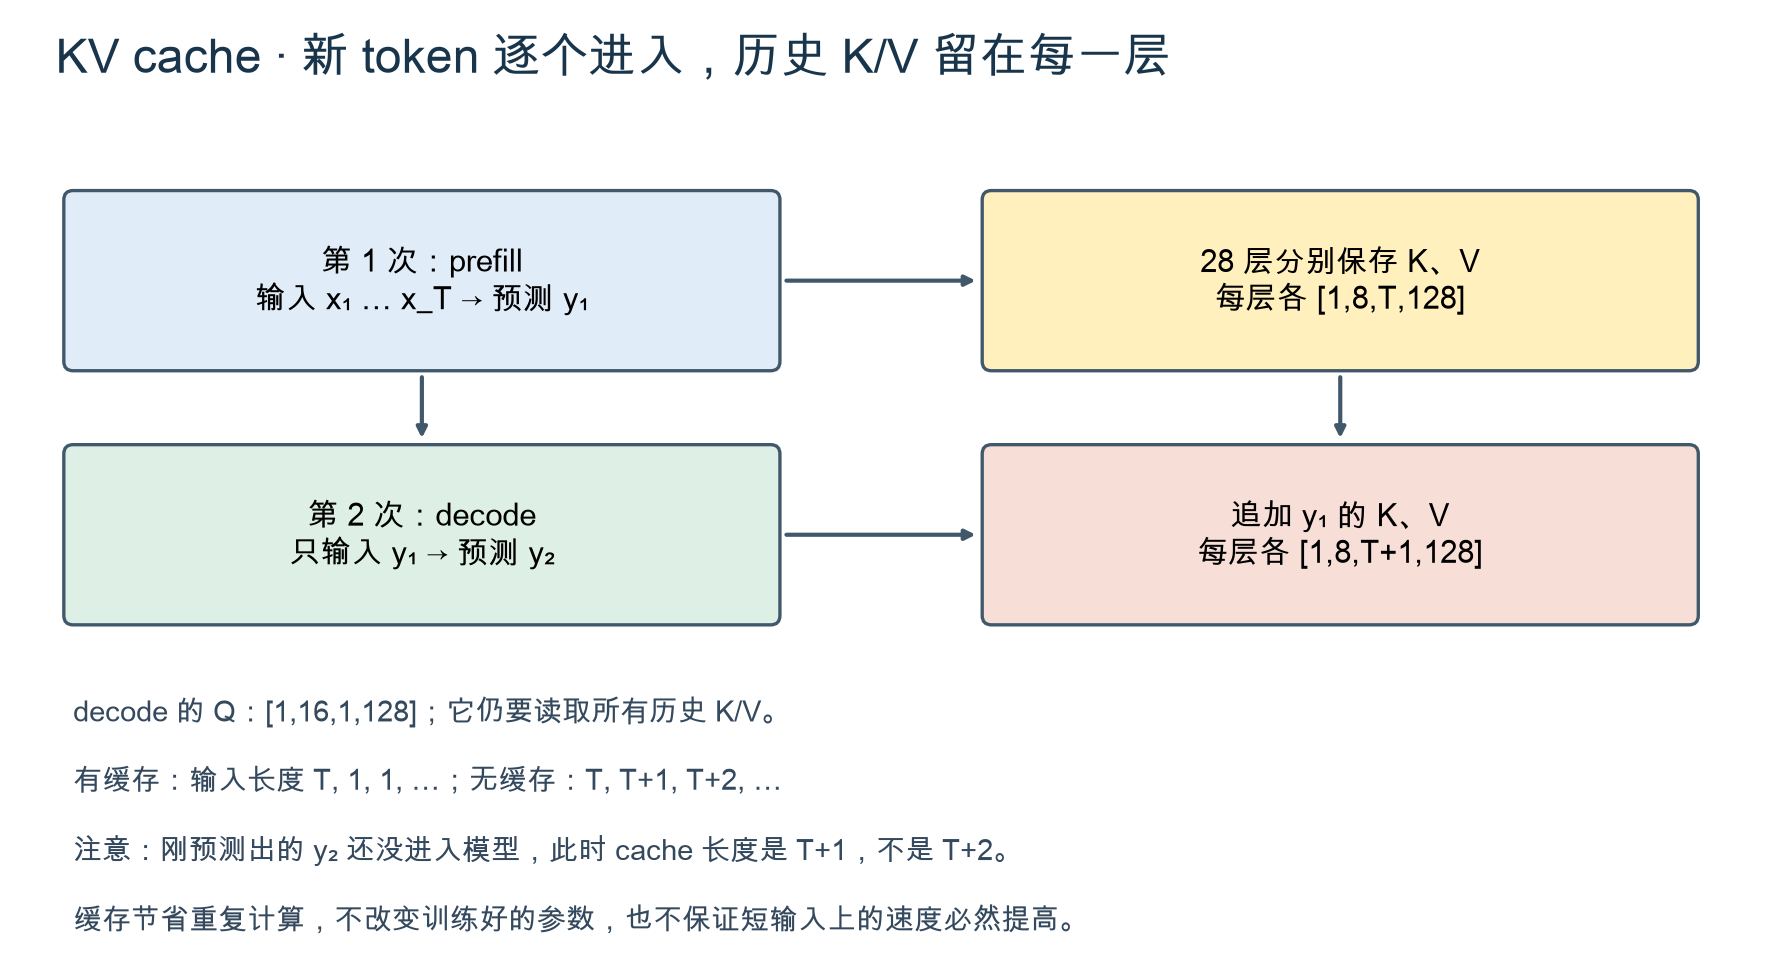

In [9]:
# 先观察真实缓存，而不是仅按公式猜尺寸。
with torch.inference_mode():
    prefill = model(**inputs, use_cache=True, logits_to_keep=1)
cache = prefill.past_key_values
k0, v0 = cache[0]
print('缓存类型:', type(cache).__name__, '| 层数:', len(cache))
print('第 0 层 K:', tuple(k0.shape), '| V:', tuple(v0.shape))
print('prefill 后 cache 长度:', cache.get_seq_length())
assert tuple(k0.shape) == (1, 8, T, 128)
cache_bytes = sum(k.numel()*k.element_size() + v.numel()*v.element_size() for k, v in cache)
print(f'全部 28 层 KV 数据: {cache_bytes / 2**20:.3f} MiB')
del prefill, cache, k0, v0

cached_run = manual_generate(model, input_ids, max_new_tokens=5, use_cache=True, verbose=True, tokenizer=tokenizer)

缓存类型: DynamicCache | 层数: 28
第 0 层 K: (1, 8, 21, 128) | V: (1, 8, 21, 128)
prefill 后 cache 长度: 21
全部 28 层 KV 数据: 4.594 MiB
{'step': 1, 'input_tokens': 21, 'cache_tokens': 21, 'token_id': 35926} 累计文本: '自'
{'step': 2, 'input_tokens': 1, 'cache_tokens': 22, 'token_id': 105162} 累计文本: '自回归'
{'step': 3, 'input_tokens': 1, 'cache_tokens': 23, 'token_id': 43959} 累计文本: '自回归生成'
{'step': 4, 'input_tokens': 1, 'cache_tokens': 24, 'token_id': 101158} 累计文本: '自回归生成是一种'


{'step': 5, 'input_tokens': 1, 'cache_tokens': 25, 'token_id': 67338} 累计文本: '自回归生成是一种通过'


上一格的第二步开始，`input_tokens` 应为 1。工具内部新增的关键行如下：

```python
current = ids[:, -1:] if cache is not None else ids
output = model(input_ids=current,
               attention_mask=torch.ones_like(ids),  # 长度包括历史 + 当前
               past_key_values=cache, use_cache=True,
               logits_to_keep=1)
cache = output.past_key_values
```

模型根据 cache 长度衔接新 token 的位置，RoPE 不能每一步都从位置 0 开始。本例无 padding；若以后支持批处理、左 padding 或复杂缓存，需要明确处理位置和 mask，不能简单照抄。

为什么能复用？因果注意力下，历史位置不能看到后来 token，`eval()` 下它们的表示不会因追加未来 token 改变。每层当前 Q 仍会读取这一层的历史 K/V。

## 8 · 验证优化前后算的是同一件事

不能只看两句话“意思差不多”。我们让两条路径输入完全相同的 token 前缀，连续 3 步比较整个词表的 logits，同时检查缓存长度。浮点运算顺序不同允许小误差；这不是训练质量评估。

In [10]:
cache_errors = check_cache(model, input_ids, steps=3)
print('每一步最大的 logit 绝对误差:', cache_errors)
print('通过：完整前缀与缓存路径在本课 float32 容差内一致，缓存长度正确。')

每一步最大的 logit 绝对误差: [3.528594970703125e-05, 3.653764724731445e-05, 3.0517578125e-05]
通过：完整前缀与缓存路径在本课 float32 容差内一致，缓存长度正确。


## 9 · 实测速度：不提前宣布“快了多少倍”

固定生成 12 步、两种路径分别预热、各测 3 次并取中位数。计时前后同步 MPS/CUDA，排除异步提交造成的虚假速度；包括 prefill 与 decode，不包含下载、分词和打印。

为了固定工作量，这个小基准忽略 EOS，不能把其文本当作正常回答。短输入下缓存管理可能抵消收益；本机结果不代表云 GPU 或长上下文性能。

In [11]:
timings = benchmark(model, input_ids, tokens=12, repeats=3)
for row in timings:
    print(f"use_cache={row['use_cache']!s:5s}  中位耗时={row['median_seconds']:.3f}s  "
          f"生成吞吐={row['tokens_per_second']:.2f} token/s")
ratio = timings[0]['median_seconds'] / timings[1]['median_seconds']
print(f'本次耗时比（无缓存/有缓存）: {ratio:.2f}')

use_cache=False  中位耗时=0.547s  生成吞吐=21.94 token/s
use_cache=True   中位耗时=0.420s  生成吞吐=28.55 token/s
本次耗时比（无缓存/有缓存）: 1.30


## 10 · 内存看三笔账

1. **参数数据**：不随 prompt 长度改变；float32 权重约 2.22 GiB。
2. **KV cache 数据**：随 batch、token 数线性增加；本模型每个历史 token 的全部层 K/V 在 float32 下共 224 KiB。
3. **实际分配**：还有激活、临时缓冲与分配器等。MPS 是统一内存，下面的快照不是峰值，也不是整个 Python 进程的 RSS。

缓存公式：`2 × B × T × 28 × 8 × 128 × 每元素字节数`。GQA 保存的是 8 个 KV 头，不是展开后的 16 个 Q 头。

In [12]:
weight_bytes = sum(p.numel()*p.element_size() for p in model.parameters())
print(f'参数张量数据: {weight_bytes/2**30:.3f} GiB（共享参数只计一次）')
print(f'当前 prompt 的 KV 数据: {cache_bytes/2**20:.3f} MiB')
memory = {'parameter_bytes': weight_bytes, 'prompt_kv_bytes': cache_bytes}
if device.type == 'mps':
    torch.mps.synchronize()
    memory.update(mps_current_allocated_bytes=torch.mps.current_allocated_memory(),
                  mps_driver_allocated_bytes=torch.mps.driver_allocated_memory())
    print('MPS 分配快照:', {k: round(v/2**20, 2) for k,v in memory.items() if k.startswith('mps')}, 'MiB')

# 小型验证记录，不保存权重、cache 或整段 logits。
report = {'kind': 'teacher_execution_not_student_completion',
          'executed_at': datetime.now().astimezone().isoformat(), 'model': MODEL_ID,
          'revision': REVISION, 'torch': torch.__version__, 'transformers': transformers.__version__,
          'device': str(device), 'machine': platform.machine(), 'dtype': str(model.dtype),
          'question': QUESTION, 'prompt_tokens': T, 'answer': answer,
          'answer_tokens': len(answer_ids), 'observed_shapes': shapes,
          'cache_max_abs_errors': cache_errors, 'timings': timings, 'memory': memory}
(LESSON/'assets'/'execution-report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2)+'\n')
print('运行记录已保存：assets/execution-report.json')

参数张量数据: 2.220 GiB（共享参数只计一次）
当前 prompt 的 KV 数据: 4.594 MiB
MPS 分配快照: {'mps_current_allocated_bytes': 2288.25, 'mps_driver_allocated_bytes': 2746.69} MiB
运行记录已保存：assets/execution-report.json


## 从这一步接到训练

现在我们能指出输入是什么、输出是什么，以及 token 是怎么一个个产生的。下一课再复用这个观察方式看训练：

| 阶段 | 输入 / 目标 | 更新什么 |
|---|---|---|
| 本课推理 | 给定 prompt，生成新 token | 不更新参数；cache 随生成增长 |
| 预训练 / 继续预训练 | 连续文本，预测真实的下一个 token | 用交叉熵和反向传播更新指定参数 |
| SFT | 对话模板，通常只对回答部分计算 loss | 更新全部参数或 LoRA 等指定参数 |
| RL | 模型生成候选，按奖励反馈优化策略 | 按相应目标更新策略参数 |

这里先停止在推理，不提前租 GPU。短输出、单次成功或较高吞吐都不构成语言能力评测；训练课会固定验证数据与指标。

需要释放模型时可以运行下面一格；之后要继续实验，应重新运行模型加载格。

参考：[固定模型版本](https://huggingface.co/Qwen/Qwen3-0.6B/tree/c1899de289a04d12100db370d81485cdf75e47ca) · [模型卡与非思考模式](https://huggingface.co/Qwen/Qwen3-0.6B) · [Transformers 4.57.3 Qwen3 实现](https://github.com/huggingface/transformers/blob/v4.57.3/src/transformers/models/qwen3/modeling_qwen3.py)。本课 helper 只支持单条无 padding 输入。

In [13]:
# 可选：结束本课后取消注释运行。
# del model
# gc.collect()
# if device.type == 'mps':
#     torch.mps.empty_cache()